In [1]:
import random
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output
from matplotlib.patches import Rectangle


class Passenger:
    def __init__(self, pid, row, seat, luggage_delay=None):
        self.pid = pid # Unique passenger ID number (e.g., 1, 2, 3...)
        self.row = row # The target row where the passenger will sit (Row 1–9 on our simulate model)
        self.seat = seat # The seat column name assigned to the passenger (A, B, C, D, E, or F)
        self.x = -1 # Current x-position in the aisle, we set x=-1 to indicate that a passenger has not entered yet
        self.y = None # Current y-position (column index), which will be set when the passenger enters the plane.
        self.seated = False # Will be used to define whether a passenger is already seated (either True or False)
        self.luggage_delay = random.randint(9, 12) # Set number of steps needed to place luggage in the overhead bin. At least 9 seconds and at most 12 seconds to place 1 luggage
        self.remaining_delay = self.luggage_delay # Remaining luggage time in seconds (counts down as simulation runs)

    def __repr__(self):
        return f"Passenger(row={self.row}, seat={self.seat}, seated={self.seated})" #learned from cell class in HW02

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch #from HW02 show function
import time #from HW02 
from IPython.display import clear_output #from HW02 
import random

class Plane:
    def __init__(self, num_rows):
        self.num_rows = num_rows
        self.seat_letters = ["A", "B", "C", "D", "E", "F"]
        self.aisle_y = 3
        self.entrance_y = 3

        # plane state
        self.passengers = []

        # seat map
        self.seats = {}
        for row in range(1, num_rows + 1):
            for seat in self.seat_letters:
                self.seats[(row, seat)] = None

    # seat letter indicates y coordinate
    def get_seat_y(self, seat):
        return {"A": 0, "B": 1, "C": 2, "D": 4, "E": 5, "F": 6}[seat]

    # add passenger to queue
    def add_passenger(self, passenger):
        passenger.x = -1
        passenger.y = self.entrance_y
        self.passengers.append(passenger)

    # sit a passenger (fill seat)
    def sit_passenger(self, passenger):
        if self.seats[(passenger.row, passenger.seat)] is None:
            self.seats[(passenger.row, passenger.seat)] = passenger
            passenger.seated = True
            return True
        return False

    # generates a list of passengers by assigning each seat to a passenger pid
    def make_passengers(self):
        passengers = []
        pid = 1
        for row in range(1, self.num_rows + 1):
            for seat in self.seat_letters:
                passengers.append(Passenger(pid, row, seat))
                pid += 1
        return passengers

    # Updated step() funtion which avoid queuing conflict
    def step(self):

        intentions = {}

        # order of movement follows queue order
        order = {p: i for i, p in enumerate(self.passengers)}

        # cells currently occupied (only aisle movers, not seated ones)
        occupied = {(p.x, p.y) for p in self.passengers
                    if (not p.seated and p.x >= 0)}

        movers = [p for p in self.passengers if not p.seated]

        for p in movers:

            # Stage 1. entering plane
            if p.x < 0:
                target = (0, self.aisle_y)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 2. walk forward in aisle until (row-1, aisle)
            if p.x < p.row - 1:
                nx = p.x + 1
                target = (nx, p.y)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 3. step sideways toward seat
            seat_y = self.get_seat_y(p.seat)

            if p.y < seat_y:
                target = (p.x, p.y + 1)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            if p.y > seat_y:
                target = (p.x, p.y - 1)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 4. luggage delay
            if p.remaining_delay > 0:
                p.remaining_delay -= 1
                intentions[p] = (p.x, p.y)
                continue

            # Stage 5. sit down
            self.sit_passenger(p)
            intentions[p] = (p.x, p.y)

        cell_to_list = {}
        for p, cell in intentions.items():
            cell_to_list.setdefault(cell, []).append(p)

        # apply moves
        for cell, plist in cell_to_list.items():
            if len(plist) == 1:
                p = plist[0]
                if not p.seated:
                    p.x, p.y = cell
            else:
                # choose winner by queue order
                winner = min(plist, key=lambda x: order[x])
                if not winner.seated:
                    winner.x, winner.y = cell
                # losers remain

    # animate run() with plot
    def run(self):
        start = time.time()
        step_count = 0
        while not all(p.seated for p in self.passengers):
            clear_output(wait=True)
            self.show()
            self.step()
            step_count += 1
            time.sleep(0.1)

        clear_output(wait=True)
        self.show()
        end = time.time()
        print(f"It took {round(end - start, 2)} seconds")

    # fast mode: Run simulation without plotting, accumulating REAL boarding time.
    # Each step represents `seconds_per_step` real seconds.
    def run_no_plot(self, seconds_per_step=0.5):
        total_time = 0.0

        while not all(p.seated for p in self.passengers):
            self.step()
            total_time += seconds_per_step

        return total_time

    # visualization (original)
    def show(self):
        for (row, seat), passenger in self.seats.items():
            y = self.get_seat_y(seat)
            color = "green" if passenger else "white"
            plt.scatter(row - 1, y, s=500, c=color, edgecolors='black')

        for p in self.passengers:
            if not p.seated:
                plt.scatter(p.x, p.y, s=500, c='red', edgecolors='black')

        plt.grid()
        plt.xticks(range(self.num_rows))
        plt.yticks(range(7))
        plt.xlim(-1, self.num_rows)
        plt.ylim(-1, 7)
        plt.show()

## Do a small check to see if it works or not

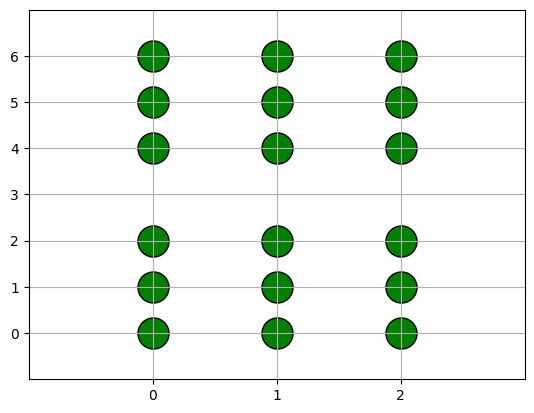

It took 30.75 seconds


In [3]:
boeing = Plane(num_rows=3)

# Genreate 3 rows × A–F = 18 passengers
passengers = boeing.make_passengers()

for p in passengers:
    boeing.add_passenger(p)

boeing.run()

## Firstly, we are wondering if letting passengers take seats from front to back and from window to aisle will make boarding efficiently

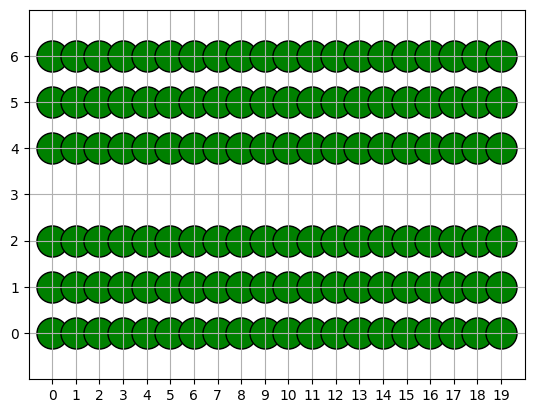

It took 325.32 seconds


In [4]:
full_boeing = Plane(num_rows=20)

passengers = full_boeing.make_passengers()

window = ["A", "F"]
middle = ["B", "E"]
aisle  = ["C", "D"]

# Front-to-Back + Window→Middle→Aisle
ordered = sorted(
    passengers,
    key=lambda p: (
        p.row, 
        0 if p.seat in window else
        1 if p.seat in middle else
        2,
        p.seat
    )
)

for p in ordered:
    full_boeing.add_passenger(p)

full_boeing.run()

## In the following case, we will do it reversely, which let passengers take seats from back to front and from window to aisle

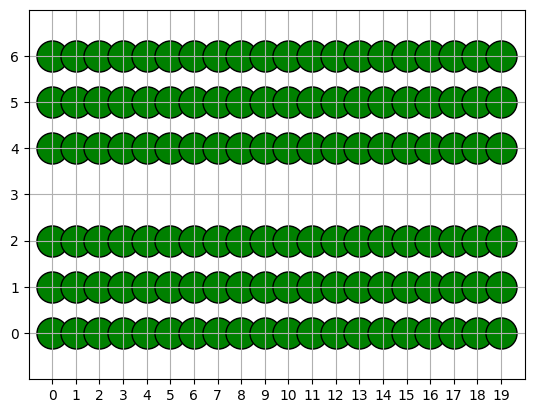

It took 308.87 seconds


In [5]:
full_reverse_order_boeing = Plane(num_rows=20)

# automatically generate 20 rows × 6 seats = 120 passengers
passengers = full_reverse_order_boeing.make_passengers()

# Seat priority: window first, then middle, finally aisle
seat_priority = {
    "A": 0, "F": 0, # window seat first
    "B": 1, "E": 1, # middle seat then
    "C": 2, "D": 2 # aisle seat final
}

reverse_order = sorted(
    passengers,
    key=lambda p: (
        -p.row,                # 1. from back to front
        seat_priority[p.seat], # 2. window first, then middle, finally aisle
        p.seat                 # 3. alphabetical order within seat group
    )
)

# make passengers enter the plane in reverse_order
for p in reverse_order:
    full_reverse_order_boeing.add_passenger(p)
    
# run simulation
full_reverse_order_boeing.run()

## As we can see from above, boarding passengers from back to front and from window to aisle is more efficient.

## According to the website cited below, we are interested in whether wilma method would be faster than that which boards passengers from back to front and from window to aisle.

### Reference: https://boardingarea.com/all-about-uniteds-new-wilma-boarding-for-frequent-flyers/

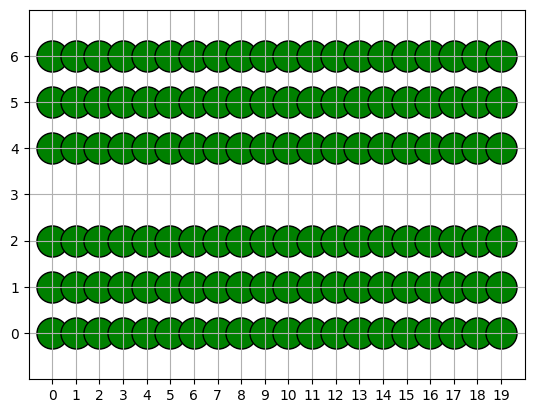

It took 308.31 seconds


In [6]:
# WILMA: The WILMA boarding method loads passengers strictly by seat type: all window-seat passengers board first, followed by all middle-seat passengers, and finally all aisle-seat passengers.

wilma_boeing = Plane(num_rows=20)

# automatically generate 20 rows × 6 seats = 120 passengers
passengers = wilma_boeing.make_passengers()

window_seats = ["A", "F"]
middle_seats = ["B", "E"]
aisle_seats  = ["C", "D"]

# WILMA order
wilma_sorted = sorted(
    passengers,
    key=lambda p: (
        0 if p.seat in window_seats else
        1 if p.seat in middle_seats else
        2,      # seat group：from window to middle, finally aisle
        -p.row  # row：back → front
    )
)

# make passengers enter the plane in wilma_sorted order
for p in wilma_sorted:
    wilma_boeing.add_passenger(p)

# run simulation
wilma_boeing.run()

### Great discovery! We found that wilma boading is the way faster than the method we thought.

## However, there are two more methods suggested by the website cited below, which are Southwest method and Steffen method.

## https://www.vox.com/2014/4/25/5647696/the-way-we-board-airplanes-makes-absolutely-no-sense

## Let's try Southwest Method first!

In [7]:
def southwest_random_seat_assignment(num_rows=20):

    seat_letters = ["A", "B", "C", "D", "E", "F"]

    # All possible seats (row, seat)
    seats = [
        (row, seat)
        for row in range(1, num_rows + 1)
        for seat in seat_letters
    ]

    # Randomize seat positions
    random.shuffle(seats)

    # Create passengers with shuffled seat assignments
    passengers = []
    for pid, (row, seat) in enumerate(seats, start=1):
        passengers.append(Passenger(pid, row, seat))

    return passengers

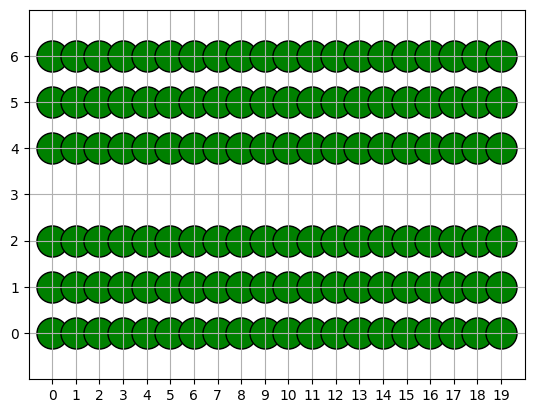

It took 331.06 seconds


In [9]:
sw_passengers = southwest_random_seat_assignment()

sw_boeing = Plane(num_rows=20)

for p in sw_passengers:
    sw_boeing.add_passenger(p)

sw_boeing.run()

In [10]:
#AI-assisted completion of the Steffen boarding method implementation
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 20, 2025
#Note: A portion of this method required clarification regarding the correct ordering logic 
#(seat-group priority and alternating-row structure), so assistance was used to refine and 
#complete the final implementation.

def steffen_boarding(passengers):
    """
    Jason Steffen boarding method (optimized boarding):
    1) Prioritize seat groups in the order: Window (A/F) → Middle (B/E) → Aisle (C/D)
    2) Within each seat group, apply an 'alternating row' pattern:
          Odd-numbered rows first, Even-numbered rows will become the alternating row
    3) Both odd and even groups are sorted back-to-front (higher row → lower row) based on our experience
    """

    window = ["A", "F"]
    middle = ["B", "E"]
    aisle  = ["C", "D"]

    def steffen_sort(group):
        """
        Sort a seat-type group using Steffen's alternating-row logic:
        - Separate passengers into odd vs. even rows
        - Sort each list from back to front
        - Return odd rows first, then even rows
        """

        odd_rows  = [p for p in group if p.row % 2 == 1]
        even_rows = [p for p in group if p.row % 2 == 0]

        # Back-to-front sorting (descending row number)
        odd_rows.sort(key=lambda p: -p.row)
        even_rows.sort(key=lambda p: -p.row)

        return odd_rows + even_rows
    
    # Categorize passengers by seat type
    window_ps = [p for p in passengers if p.seat in window]
    middle_ps = [p for p in passengers if p.seat in middle]
    aisle_ps  = [p for p in passengers if p.seat in aisle]

    # Apply Steffen ordering for each seat category
    ordered = []
    ordered += steffen_sort(window_ps)
    ordered += steffen_sort(middle_ps)
    ordered += steffen_sort(aisle_ps)

    return ordered

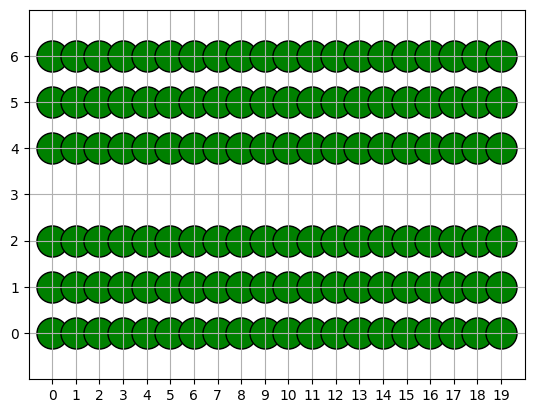

It took 310.42 seconds


In [12]:
steffen_boeing = Plane(20)
passengers = steffen_boeing.make_passengers()
ordered = steffen_boarding(passengers)
for p in ordered:
    steffen_boeing.add_passenger(p)

steffen_boeing.run()

## We found that there is not very much time difference between the Steffen method and wilma method. Thus, we would like to randomly run these methods 1000 times and calculate their mean time in second. 

In [13]:
#AI-generated code for applying multiple boarding strategies (similar to R's apply)
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 20, 2025
#Prompt: "I am writing a function which applies several plane boarding strategies using a list of 
# functions, runs each strategy 1000 times with random passengers. Could you please help me deal with the for loop so that it can compute the average 
# boarding time using measure_strategy(), and returns all results in a clean dictionary or table."

def measure_strategy(strategy_function, n=100, num_rows=20, seconds_per_step=0.5):
    total = 0

    for _ in range(n):

        plane = Plane(num_rows)

        # Try queue-based strategy first (expects passengers)
        try:
            passengers = plane.make_passengers()
            ordered = strategy_function(passengers)

        # If fails, then it's Southwest (expects num_rows)
        except TypeError:
            ordered = strategy_function(num_rows)

        # Load passengers
        for p in ordered:
            plane.add_passenger(p)

        total += plane.run_no_plot(seconds_per_step)

    avg = total / n
    print(f"{strategy_function.__name__}: average = {avg:.2f} seconds over {n} runs")
    return avg

In [14]:
# This is a simple function for WILMA Method which all Window seats board first, followed by middle seats, and aisle seats last.
# Within each seat group, passengers board from back to front to minimize aisle congestion.
def wilma_boarding(passengers):
    window_seats = ["A", "F"]
    middle_seats = ["B", "E"]
    aisle_seats = ["C", "D"]

    # WILMA = Window, then Middle, then Aisle
    sorted_list = sorted(
        passengers,
        key=lambda p: (
            0 if p.seat in window_seats else
            1 if p.seat in middle_seats else
            2,
            -p.row
        )
    )
    return sorted_list

In [15]:
measure_strategy(wilma_boarding, n=1000, seconds_per_step=1.5)

wilma_boarding: average = 377.42 seconds over 1000 runs


377.4195

In [17]:
measure_strategy(southwest_random_seat_assignment, n=1000,seconds_per_step=1.5)

southwest_random_seat_assignment: average = 412.92 seconds over 1000 runs


412.9185

In [18]:
measure_strategy(steffen_boarding, n=1000,seconds_per_step=1.5)

steffen_boarding: average = 378.85 seconds over 1000 runs


378.8535

### Based on the average time in second which calculated from randomly running 1000 times, we would say that the wilma boarding is the most efficient way to boarding passengers.